---
title: Implementasi Interpolasi Polinomial (Modifikasi Tugas 3)
---

## Pendahuluan

### Review Tugas 4

Pada tugas ke-4, hasil ekstraksi fitur TSFEL dari seluruh mahasiswa (19 orang) digabungkan menjadi satu dataset berukuran **19 baris × 274 kolom** (68 fitur × 4 polutan + 2 kolom identitas). Dataset gabungan ini kemudian diproses di **KNIME** dengan alur:

1. Normalisasi Z-Score
2. Reduksi dimensi PCA
3. Clustering K-Means

Tujuannya adalah untuk mengelompokkan daerah berdasarkan kemiripan pola polutan atmosfer.

Satu hal penting yang perlu dicatat adalah bahwa seluruh pipeline dari tugas ke-1 hingga ke-4 menggunakan **Interpolasi Linier** (`method='linear'`) untuk menangani _missing values_ pada data time series polutan. Metode ini dipilih karena sederhana dan mampu menjaga kontinuitas temporal, namun memiliki keterbatasan: interpolasi linier hanya memperhitungkan dua titik data terdekat (sebelum dan sesudah _gap_), sehingga hasil estimasinya selalu berupa garis lurus di antara kedua titik tersebut. Untuk data yang memiliki pola non-linear (misalnya fluktuasi musiman atau tren melengkung), pendekatan ini bisa kurang akurat.

### Interpolasi Polinomial

**Interpolasi Polinomial** adalah metode estimasi nilai di antara titik-titik data yang diketahui menggunakan fungsi polinomial berderajat $n$. Berbeda dengan interpolasi linier yang hanya menggunakan polinomial derajat 1 (garis lurus), interpolasi polinomial mampu menghasilkan kurva yang lebih fleksibel karena memperhitungkan lebih banyak titik data di sekitar _gap_.

Secara matematis, diberikan $n+1$ titik data $(x_0, y_0), (x_1, y_1), \ldots, (x_n, y_n)$, terdapat tepat satu polinomial berderajat paling tinggi $n$ yang melewati semua titik tersebut:

$$P(x) = a_0 + a_1 x + a_2 x^2 + \cdots + a_n x^n$$

Keunggulan interpolasi polinomial dibandingkan interpolasi linier:

- Mampu menangkap **pola non-linear** seperti tren melengkung atau fluktuasi musiman pada data time series.
- Menghasilkan transisi yang lebih **halus (_smooth_)** di antara titik-titik data.
- Memperhitungkan **lebih banyak titik data tetangga**, sehingga estimasi di area _gap_ lebih kontekstual.

Namun, perlu diperhatikan bahwa derajat polinomial yang terlalu tinggi dapat menyebabkan **osilasi berlebihan** (_Runge's phenomenon_), terutama di tepi interval data. Oleh karena itu, pemilihan derajat polinomial perlu dilakukan dengan hati-hati.

## Apa yang Akan Dilakukan?

Secara garis besar, yang akan dilakukan di tugas 5.1 ini adalah **memodifikasi Tugas 3**, tepatnya pada bagian penanganan _missing values_ yang sebelumnya menggunakan metode **Interpolasi Linier**, akan diganti menggunakan metode **Interpolasi Polinomial**.

Modifikasi tidak akan dilakukan secara langsung di file `tugas_3.ipynb`. Sebagai gantinya, kode akan ditulis ulang dari awal dengan menggunakan dataset mentah yang telah dihasilkan oleh **Tugas 1** (`data_kualitas_udara_modifikasi.csv`) sebagai titik awal.

Alur yang akan dikerjakan:

1. **Memuat dataset** hasil Tugas 1 yang masih mengandung _missing values_.
2. **Menangani _missing values_** menggunakan Interpolasi Polinomial (`method='polynomial'`).
3. **Mendeteksi dan menangani _outlier_** menggunakan metode IQR + _Capping/Winsorization_ (sama seperti Tugas 3).
4. **Mengekstraksi fitur** menggunakan TSFEL (68 fitur per polutan).
5. **Menggabungkan** hasil ekstraksi fitur ke dalam satu dataset akhir.

Setelah hasil akhir didapatkan, dataset fitur ini akan digabungkan dengan hasil mahasiswa lain untuk kemudian digunakan pada tahap clustering, sama seperti alur yang telah dilakukan pada Tugas 4.

## Implementasi

### Mencari dan Menangani Missing Values

#### 1. Memuat Dataset dan Identifikasi Awal Missing Values

Langkah pertama adalah memuat dataset mentah hasil Tugas 1 (`data_kualitas_udara_modifikasi.csv`) yang berisi 365 baris data harian untuk 4 polutan (CO, NO2, SO2, CH4). Kemudian dilakukan identifikasi jumlah dan persentase _missing values_ pada setiap kolom.

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [28]:
df = pd.read_csv("../tugas-1/data_kualitas_udara_modifikasi.csv")
df.head()

,date,CO,NO2,SO2,CH4
0,2025-08-24,0.031457,NaN,0.000324,NaN
1,2025-08-25,0.033329,0.000067,0.000719,NaN
2,2025-08-26,0.033329,0.000059,0.000905,NaN
3,2025-08-27,0.033755,0.000059,0.000790,NaN
4,2025-08-28,0.032358,0.000059,0.000790,NaN


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    365 non-null    object 
 1   CO      258 non-null    float64
 2   NO2     257 non-null    float64
 3   SO2     258 non-null    float64
 4   CH4     200 non-null    float64
dtypes: float64(4), object(1)
memory usage: 14.4+ KB


In [30]:
missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({
    'Jumlah Missing (Baris)': missing_count,
    'Persentase Missing (%)': missing_percentage.round(2)
})

missing_summary

,Jumlah Missing (Baris),Persentase Missing (%)
date,0,0.00
CO,107,29.32
NO2,108,29.59
SO2,107,29.32
CH4,165,45.21


#### 2. Analisis Pola dan Visualisasi Missing Values

Selanjutnya, dilakukan analisis pola _missing values_ dengan menampilkan baris-baris yang mengandung nilai kosong, serta memvisualisasikan sebaran titik-titik _missing_ pada grafik deret waktu setiap polutan.

In [31]:
df_missing_rows = df[df.isnull().any(axis=1)]
df_missing_rows.head(15)

,date,CO,NO2,SO2,CH4
0,2025-08-24,0.031457,NaN,0.000324,NaN
1,2025-08-25,0.033329,0.000067,0.000719,NaN
2,2025-08-26,0.033329,0.000059,0.000905,NaN
3,2025-08-27,0.033755,0.000059,0.000790,NaN
4,2025-08-28,0.032358,0.000059,0.000790,NaN
5,2025-08-29,NaN,NaN,NaN,NaN
15,2025-09-08,NaN,NaN,NaN,NaN
37,2025-09-30,NaN,NaN,NaN,NaN
38,2025-10-01,NaN,NaN,NaN,NaN
56,2025-10-19,NaN,NaN,NaN,NaN


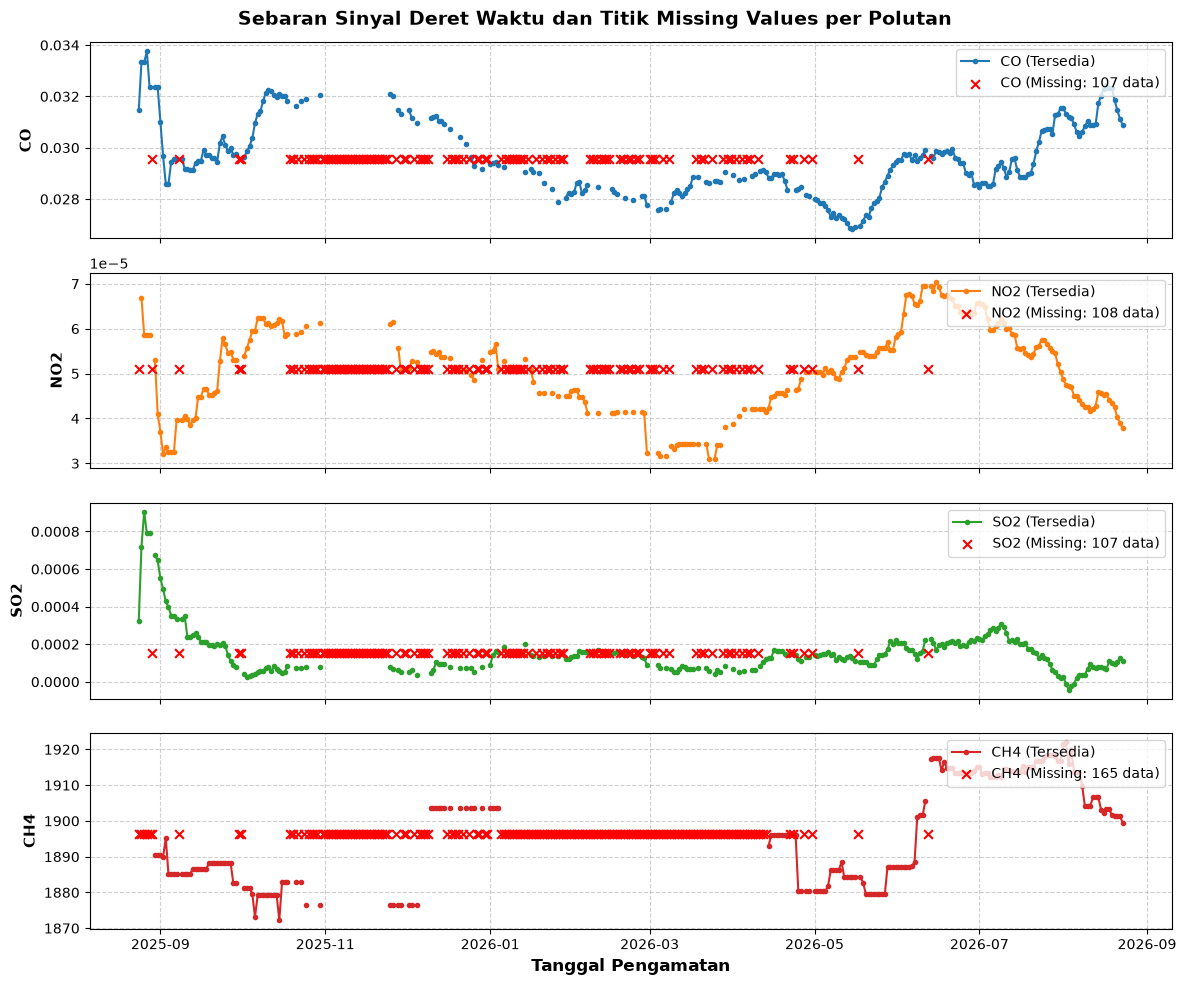

In [32]:
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
pollutants = ['CO', 'NO2', 'SO2', 'CH4']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

df_plot = df.copy()
df_plot['date'] = pd.to_datetime(df_plot['date'])

for i, p in enumerate(pollutants):
    axes[i].plot(df_plot['date'], df_plot[p], label=f'{p} (Tersedia)', color=colors[i], marker='o', markersize=3, linestyle='-')
    null_mask = df_plot[p].isnull()
    if null_mask.sum() > 0:
        null_dates = df_plot.loc[null_mask, 'date']
        axes[i].scatter(null_dates, [df_plot[p].dropna().mean()] * len(null_dates), color='red', marker='x', s=40, label=f'{p} (Missing: {null_mask.sum()} data)', zorder=5)
    axes[i].set_ylabel(p, fontsize=11, fontweight='bold')
    axes[i].legend(loc='upper right')
    axes[i].grid(True, linestyle='--', alpha=0.6)

axes[-1].set_xlabel('Tanggal Pengamatan', fontsize=12, fontweight='bold')
plt.suptitle('Sebaran Sinyal Deret Waktu dan Titik Missing Values per Polutan', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

#### 3. Penanganan Missing Values Menggunakan Metode Interpolasi Polinomial

##### Pemilihan Metode Imputasi: Interpolasi Polinomial

Pada Tugas 3, penanganan _missing values_ menggunakan **Interpolasi Linier** (`method='linear'`). Kali ini, metode yang digunakan adalah **Interpolasi Polinomial** (`method='polynomial'`) dengan derajat 3 (`order=3` / kubik). Interpolasi polinomial mampu menangkap pola non-linear pada data deret waktu, sehingga estimasi di area _gap_ menghasilkan kurva yang lebih halus dan kontekstual.

Perlu dicatat bahwa interpolasi polinomial memerlukan titik referensi data di kedua sisi _gap_ (sebelum dan sesudah) untuk mengonstruksi kurva polinomial, sehingga nilai kosong di batas paling awal deret waktu (seperti pada **NO2** indeks 0 dan **CH4** indeks 0–5) tidak dapat diekstrapolasi langsung oleh kurva polinomial. Oleh karena itu, kita melengkapinya dengan chaining `.bfill().ffill()` (*backward fill* dan *forward fill*) untuk memastikan batas-batas ujung data terisi penuh tanpa menyisakan *missing values*.

##### Melakukan Imputasi Interpolasi Polinomial pada Seluruh Kolom Polutan

Kita membuat salinan _dataframe_ `df_imputed` kemudian menerapkan metode `.interpolate(method='polynomial', order=3, limit_direction='both').bfill().ffill()` pada seluruh kolom polutan (**CO**, **NO2**, **SO2**, dan **CH4**).

In [33]:
df_imputed = df.copy()
for p in ['CO', 'NO2', 'SO2', 'CH4']:
    df_imputed[p] = df_imputed[p].interpolate(method='polynomial', order=3, limit_direction='both').bfill().ffill()

df_imputed.head(10)

,date,CO,NO2,SO2,CH4
0,2025-08-24,0.031457,0.000067,0.000324,1890.448730
1,2025-08-25,0.033329,0.000067,0.000719,1890.448730
2,2025-08-26,0.033329,0.000059,0.000905,1890.448730
3,2025-08-27,0.033755,0.000059,0.000790,1890.448730
4,2025-08-28,0.032358,0.000059,0.000790,1890.448730
5,2025-08-29,0.031913,0.000059,0.000743,1890.448730
6,2025-08-30,0.032358,0.000053,0.000674,1890.448730
7,2025-08-31,0.032358,0.000041,0.000646,1890.448730
8,2025-09-01,0.030997,0.000037,0.000551,1890.448730
9,2025-09-02,0.029674,0.000032,0.000494,1889.981628


#### 4. Evaluasi dan Verifikasi Hasil Imputasi

##### Memeriksa Ketiadaan Nilai Kosong Pasca-Imputasi

Setelah proses imputasi selesai dijalankan, kita memeriksa kembali jumlah _missing values_ pada seluruh kolom untuk memastikan bahwa seluruh atribut kini memiliki data lengkap tanpa ada nilai kosong (_NaN_) yang tersisa.

In [34]:
df_imputed.isnull().sum()

date    0
CO      0
NO2     0
SO2     0
CH4     0
dtype: int64

##### Visualisasi Perbandingan Sinyal Sebelum dan Sesudah Imputasi

Untuk memvalidasi bahwa hasil interpolasi polinomial menyatu secara mulus dengan sinyal asli dan tidak mendistorsi tren umum data, kita membuat grafik perbandingan antara sinyal sebelum imputasi (garis solid berwarna) dengan sinyal hasil imputasi (garis putus-putus hitam).

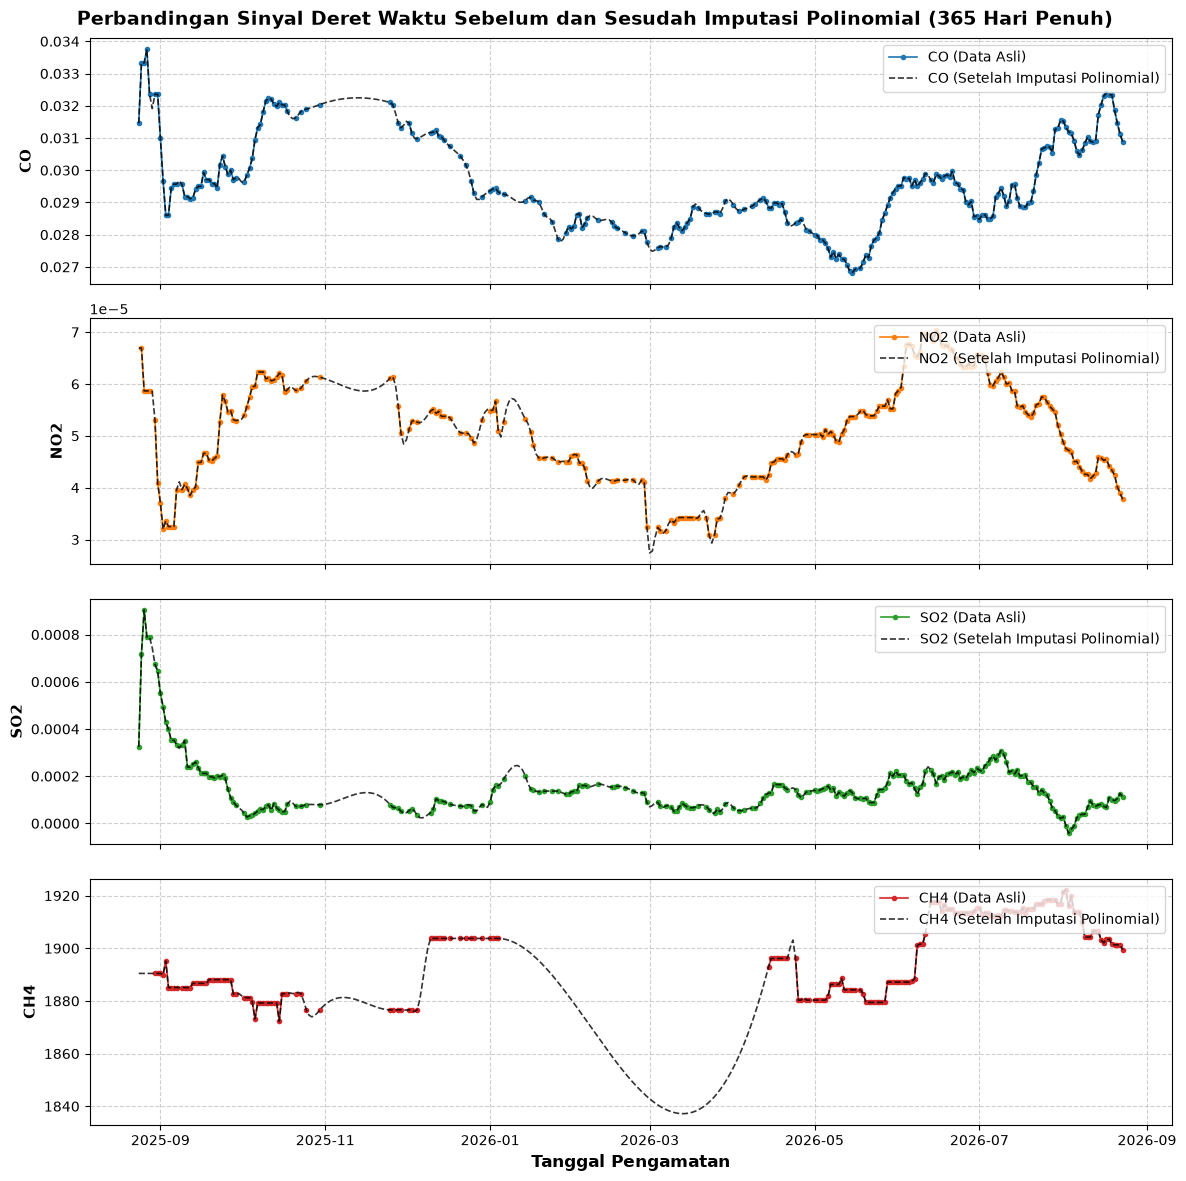

In [35]:
fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True)
pollutants = ['CO', 'NO2', 'SO2', 'CH4']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

df_imputed_plot = df_imputed.copy()
df_imputed_plot['date'] = pd.to_datetime(df_imputed_plot['date'])

for i, p in enumerate(pollutants):
    axes[i].plot(df_plot['date'], df_plot[p], label=f'{p} (Data Asli)', color=colors[i], marker='o', markersize=3, linewidth=1.2)
    axes[i].plot(df_imputed_plot['date'], df_imputed_plot[p], label=f'{p} (Setelah Imputasi Polinomial)', color='black', linestyle='--', linewidth=1.2, alpha=0.8)
    axes[i].set_ylabel(p, fontsize=11, fontweight='bold')
    axes[i].legend(loc='upper right')
    axes[i].grid(True, linestyle='--', alpha=0.6)

axes[-1].set_xlabel('Tanggal Pengamatan', fontsize=12, fontweight='bold')
plt.suptitle('Perbandingan Sinyal Deret Waktu Sebelum dan Sesudah Imputasi Polinomial (365 Hari Penuh)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

##### Menyimpan Dataset Bersih Hasil Imputasi

Setelah diverifikasi lengkap dan valid, dataset hasil imputasi disimpan ke dalam berkas CSV bernama `data_kualitas_udara_imputed.csv`. Berkas ini akan menjadi dasar untuk tahapan identifikasi serta penanganan _outlier_, dilanjutkan ke tahap ekstraksi fitur menggunakan TSFEL.

In [36]:
output_imputed_csv = 'data_kualitas_udara_imputed.csv'
df_imputed.to_csv(output_imputed_csv, index=False)
print(f"Dataset hasil imputasi berhasil disimpan ke '{output_imputed_csv}' dengan ukuran {df_imputed.shape}.")

Dataset hasil imputasi berhasil disimpan ke 'data_kualitas_udara_imputed.csv' dengan ukuran (365, 5).


### Mengidentifikasi dan Menangani Outlier

Setelah dataset bersih dari _missing values_, langkah berikutnya adalah mengidentifikasi dan menangani nilai pencilan (_outlier_). Metode yang digunakan adalah **IQR (*Interquartile Range*) / Tukey's Fences** untuk deteksi, dan teknik **Capping / Winsorization** untuk penanganan. Teknik Capping dipilih agar kontinuitas temporal deret waktu 365 hari tetap terjaga tanpa menghapus baris data.

In [37]:
# Memuat dataset hasil imputasi polinomial
df_imputed = pd.read_csv('data_kualitas_udara_imputed.csv')

pollutants = ['CO', 'NO2', 'SO2', 'CH4']
outlier_stats = []

for p in pollutants:
    q1 = df_imputed[p].quantile(0.25)
    q3 = df_imputed[p].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_mask = (df_imputed[p] < lower_bound) | (df_imputed[p] > upper_bound)
    outlier_count = outlier_mask.sum()
    outlier_pct = (outlier_count / len(df_imputed)) * 100
    
    outlier_stats.append({
        'Polutan': p,
        'Q1 (25%)': q1,
        'Q3 (75%)': q3,
        'IQR': iqr,
        'Batas Bawah': lower_bound,
        'Batas Atas': upper_bound,
        'Jumlah Outlier': outlier_count,
        'Persentase (%)': round(outlier_pct, 2)
    })

df_outlier_summary = pd.DataFrame(outlier_stats)
df_outlier_summary

,Polutan,Q1 (25%),Q3 (75%),IQR,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase (%)
0,CO,0.028573,0.031015,0.002442,0.024910,0.034678,0,0.00
1,NO2,0.000043,0.000059,0.000016,0.000019,0.000083,0,0.00
2,SO2,0.000075,0.000169,0.000093,-0.000065,0.000309,18,4.93
3,CH4,1877.733385,1903.675586,25.942202,1838.820082,1942.588889,13,3.56


Nilai yang berada di luar batas ambang $[Q1 - 1.5 \times IQR, Q3 + 1.5 \times IQR]$ dibatasi (*capping/winsorization*) ke nilai batas tersebut. Setelah proses Capping selesai, kita memverifikasi bahwa tidak ada lagi outlier yang tersisa, kemudian menyimpan dataset bersih ke berkas `data_kualitas_udara_clean.csv`.

In [38]:
# Menerapkan Capping pada seluruh polutan berdasarkan batas IQR
df_clean = df_imputed.copy()

for p in pollutants:
    q1 = df_clean[p].quantile(0.25)
    q3 = df_clean[p].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    df_clean[p] = df_clean[p].clip(lower=lower_bound, upper=upper_bound)

# Menyimpan dataframe bersih ke dalam berkas CSV baru
output_clean_csv = 'data_kualitas_udara_clean.csv'
df_clean.to_csv(output_clean_csv, index=False)
print(f"Dataset bersih bebas outlier berhasil disimpan ke '{output_clean_csv}' dengan ukuran {df_clean.shape}.")
df_clean.head()

Dataset bersih bebas outlier berhasil disimpan ke 'data_kualitas_udara_clean.csv' dengan ukuran (365, 5).


,date,CO,NO2,SO2,CH4
0,2025-08-24,0.031457,0.000067,0.000309,1890.44873
1,2025-08-25,0.033329,0.000067,0.000309,1890.44873
2,2025-08-26,0.033329,0.000059,0.000309,1890.44873
3,2025-08-27,0.033755,0.000059,0.000309,1890.44873
4,2025-08-28,0.032358,0.000059,0.000309,1890.44873


### Ekstraksi Fitur dengan TSFEL

Tahap berikutnya adalah melakukan ekstraksi fitur deret waktu menggunakan _library_ **TSFEL (*Time Series Feature Extraction Library*)**. Sebanyak **68 fitur** (mencakup domain statistik, temporal, dan spektral) diekstraksi dari masing-masing polutan (CO, NO2, SO2, dan CH4).

In [39]:
import tsfel
from tsfel.feature_extraction import *

def extract_68_tsfel_features(signal, fs=1):
    s = np.array(signal, dtype=float)
    
    def extract_val(v):
        if isinstance(v, dict) and 'values' in v:
            arr = v['values']
            return float(arr[0]) if len(arr) > 0 else 0.0
        elif isinstance(v, (list, tuple, np.ndarray)):
            return float(v[0]) if len(v) > 0 else 0.0
        elif isinstance(v, (int, float, np.number)):
            return float(v)
        else:
            try:
                return float(v)
            except:
                return 0.0

    funcs = [
        ('f1_abs_energy', lambda: abs_energy(s)),
        ('f2_auc', lambda: auc(s, fs)),
        ('f3_autocorr', lambda: autocorr(s)),
        ('f4_average_power', lambda: average_power(s, fs)),
        ('f5_calc_centroid', lambda: calc_centroid(s, fs)),
        ('f6_calc_max', lambda: calc_max(s)),
        ('f7_calc_mean', lambda: calc_mean(s)),
        ('f8_calc_median', lambda: calc_median(s)),
        ('f9_calc_min', lambda: calc_min(s)),
        ('f10_calc_std', lambda: calc_std(s)),
        ('f11_calc_var', lambda: calc_var(s)),
        ('f12_dfa', lambda: dfa(s)),
        ('f13_distance', lambda: distance(s)),
        ('f14_ecdf', lambda: ecdf(s)),
        ('f15_ecdf_percentile', lambda: ecdf_percentile(s)),
        ('f16_ecdf_percentile_count', lambda: ecdf_percentile_count(s)),
        ('f17_ecdf_slope', lambda: ecdf_slope(s)),
        ('f18_entropy', lambda: entropy(s)),
        ('f19_fundamental_frequency', lambda: fundamental_frequency(s, fs)),
        ('f20_higuchi_fractal_dimension', lambda: higuchi_fractal_dimension(s)),
        ('f21_hist_mode', lambda: hist_mode(s)),
        ('f22_human_range_energy', lambda: human_range_energy(s, fs)),
        ('f23_hurst_exponent', lambda: hurst_exponent(s)),
        ('f24_interq_range', lambda: interq_range(s)),
        ('f25_kurtosis', lambda: kurtosis(s)),
        ('f26_lempel_ziv', lambda: lempel_ziv(s)),
        ('f27_lpcc', lambda: lpcc(s)),
        ('f28_max_frequency', lambda: max_frequency(s, fs)),
        ('f29_max_power_spectrum', lambda: max_power_spectrum(s, fs)),
        ('f30_maximum_fractal_length', lambda: maximum_fractal_length(s)),
        ('f31_mean_abs_deviation', lambda: mean_abs_deviation(s)),
        ('f32_mean_abs_diff', lambda: mean_abs_diff(s)),
        ('f33_mean_diff', lambda: mean_diff(s)),
        ('f34_median_abs_deviation', lambda: median_abs_deviation(s)),
        ('f35_median_abs_diff', lambda: median_abs_diff(s)),
        ('f36_median_diff', lambda: median_diff(s)),
        ('f37_median_frequency', lambda: median_frequency(s, fs)),
        ('f38_mfcc', lambda: mfcc(s, fs)),
        ('f39_mse', lambda: mse(s)),
        ('f40_negative_turning', lambda: negative_turning(s)),
        ('f41_neighbourhood_peaks', lambda: neighbourhood_peaks(s)),
        ('f42_petrosian_fractal_dimension', lambda: petrosian_fractal_dimension(s)),
        ('f43_pk_pk_distance', lambda: pk_pk_distance(s)),
        ('f44_positive_turning', lambda: positive_turning(s)),
        ('f45_power_bandwidth', lambda: power_bandwidth(s, fs)),
        ('f46_rms', lambda: rms(s)),
        ('f47_skewness', lambda: skewness(s)),
        ('f48_slope', lambda: slope(s)),
        ('f49_spectral_centroid', lambda: spectral_centroid(s, fs)),
        ('f50_spectral_decrease', lambda: spectral_decrease(s, fs)),
        ('f51_spectral_distance', lambda: spectral_distance(s, fs)),
        ('f52_spectral_entropy', lambda: spectral_entropy(s, fs)),
        ('f53_spectral_kurtosis', lambda: spectral_kurtosis(s, fs)),
        ('f54_spectral_positive_turning', lambda: spectral_positive_turning(s, fs)),
        ('f55_spectral_roll_off', lambda: spectral_roll_off(s, fs)),
        ('f56_spectral_roll_on', lambda: spectral_roll_on(s, fs)),
        ('f57_spectral_skewness', lambda: spectral_skewness(s, fs)),
        ('f58_spectral_slope', lambda: spectral_slope(s, fs)),
        ('f59_spectral_spread', lambda: spectral_spread(s, fs)),
        ('f60_spectral_variation', lambda: spectral_variation(s, fs)),
        ('f61_spectrogram_mean_coeff', lambda: spectrogram_mean_coeff(s, fs)),
        ('f62_sum_abs_diff', lambda: sum_abs_diff(s)),
        ('f63_wavelet_abs_mean', lambda: wavelet_abs_mean(s, fs)),
        ('f64_wavelet_energy', lambda: wavelet_energy(s, fs)),
        ('f65_wavelet_entropy', lambda: wavelet_entropy(s, fs)),
        ('f66_wavelet_std', lambda: wavelet_std(s, fs)),
        ('f67_wavelet_var', lambda: wavelet_var(s, fs)),
        ('f68_zero_cross', lambda: zero_cross(s))
    ]
    
    feats = {}
    for name, f in funcs:
        try:
            feats[name] = extract_val(f())
        except:
            feats[name] = 0.0
            
    return feats

print("Fungsi ekstraksi 68 fitur TSFEL siap digunakan.")

Fungsi ekstraksi 68 fitur TSFEL siap digunakan.


Kita mengeksekusi fungsi ekstraksi fitur untuk seluruh polutan, kemudian menyimpan hasil masing-masing polutan ke berkas CSV individual (`output_tsfel_co.csv`, `output_tsfel_no2.csv`, `output_tsfel_so2.csv`, `output_tsfel_ch4.csv`), serta berkas gabungan seluruh polutan (`output_tsfel_all_pollutants.csv`).

In [40]:
# Ekstraksi fitur untuk masing-masing polutan
co_feats = extract_68_tsfel_features(df_clean['CO'])
no2_feats = extract_68_tsfel_features(df_clean['NO2'])
so2_feats = extract_68_tsfel_features(df_clean['SO2'])
ch4_feats = extract_68_tsfel_features(df_clean['CH4'])

# Menyimpan hasil ekstraksi fitur individual per polutan
df_tsfel_co = pd.DataFrame([co_feats])
df_tsfel_no2 = pd.DataFrame([no2_feats])
df_tsfel_so2 = pd.DataFrame([so2_feats])
df_tsfel_ch4 = pd.DataFrame([ch4_feats])

df_tsfel_co.to_csv('output_tsfel_co.csv', index=False)
df_tsfel_no2.to_csv('output_tsfel_no2.csv', index=False)
df_tsfel_so2.to_csv('output_tsfel_so2.csv', index=False)
df_tsfel_ch4.to_csv('output_tsfel_ch4.csv', index=False)

# Menggabungkan keempat dataframe fitur menjadi satu matriks fitur (4 baris x 69 kolom)
pollutant_dfs = []
for p, f_dict in [('CO', co_feats), ('NO2', no2_feats), ('SO2', so2_feats), ('CH4', ch4_feats)]:
    row = pd.DataFrame([f_dict])
    row.insert(0, 'polutan', p)
    pollutant_dfs.append(row)

df_tsfel_all = pd.concat(pollutant_dfs, ignore_index=True)
df_tsfel_all.to_csv('output_tsfel_all_pollutants.csv', index=False)

print("Ekstraksi fitur TSFEL selesai:")
print(f"- output_tsfel_co.csv: {df_tsfel_co.shape}")
print(f"- output_tsfel_no2.csv: {df_tsfel_no2.shape}")
print(f"- output_tsfel_so2.csv: {df_tsfel_so2.shape}")
print(f"- output_tsfel_ch4.csv: {df_tsfel_ch4.shape}")
print(f"- output_tsfel_all_pollutants.csv: {df_tsfel_all.shape}")
df_tsfel_all.iloc[:, :8]

/home/zkyzors/Documents/dev-stuff/learn/proyek-data-sains/.venv/lib/python3.13/site-packages/tsfel/feature_extraction/features_utils.py:534: RuntimeWarning: invalid value encountered in divide
  rs = np.divide(r, s)
/home/zkyzors/Documents/dev-stuff/learn/proyek-data-sains/.venv/lib/python3.13/site-packages/tsfel/feature_extraction/features_utils.py:534: RuntimeWarning: invalid value encountered in divide
  rs = np.divide(r, s)


Ekstraksi fitur TSFEL selesai:
- output_tsfel_co.csv: (1, 68)
- output_tsfel_no2.csv: (1, 68)
- output_tsfel_so2.csv: (1, 68)
- output_tsfel_ch4.csv: (1, 68)
- output_tsfel_all_pollutants.csv: (4, 69)


,polutan,f1_abs_energy,f2_auc,f3_autocorr,f4_average_power,f5_calc_centroid,f6_calc_max,f7_calc_mean
0,CO,3.229908e-01,10.812469,48.0,8.873374e-04,178.120226,0.033755,0.029709
1,NO2,9.766048e-07,0.018495,32.0,2.682980e-09,182.613716,0.000070,0.000051
2,SO2,8.351740e-06,0.048251,16.0,2.294434e-08,169.778228,0.000309,0.000132
3,CH4,1.298546e+09,686516.659406,34.0,3.567435e+06,182.735353,1922.044482,1886.059223


### Memasukkan Data Hasil Ekstraksi ke Dalam Data Merged

Setelah seluruh fitur berhasil diekstraksi, data fitur milik penulis (**Wildan Haydar Amru**, daerah: **Krian**) dimasukkan ke dalam berkas Excel kelas `merged_polynomial-without_me.xlsx` pada seluruh _sheet_ (`Semua Fitur`, `CO`, `SO2`, `CH4`, dan `NO2`), sehingga dataset menjadi lengkap 20 baris data observasi.

In [41]:
excel_file = 'merged_polynomial-without_me.xlsx'

# Membaca seluruh sheet dari berkas Excel yang ada
xl = pd.ExcelFile(excel_file)
sheets_dict = {}

nama_penulis = 'Wildan Haydar Amru'
daerah_penulis = 'Krian'

# Helper untuk mengubah kunci 'f1_abs_energy' -> 'abs_energy'
def clean_feature_dict(f_dict):
    return {k.split('_', 1)[1]: v for k, v in f_dict.items()}

clean_co = clean_feature_dict(co_feats)
clean_so2 = clean_feature_dict(so2_feats)
clean_ch4 = clean_feature_dict(ch4_feats)
clean_no2 = clean_feature_dict(no2_feats)

pollutant_cleaned = {
    'CO': clean_co,
    'SO2': clean_so2,
    'CH4': clean_ch4,
    'NO2': clean_no2
}

# 1. Update sheet individual (CO, SO2, CH4, NO2)
for p in ['CO', 'SO2', 'CH4', 'NO2']:
    df_p = xl.parse(p)
    # Hapus baris penulis jika sudah ada sebelumnya untuk menghindari duplikasi
    df_p = df_p[df_p['Nama'].str.strip() != nama_penulis]
    row_p = {'Nama': nama_penulis, 'Daerah': daerah_penulis}
    row_p.update(pollutant_cleaned[p])
    df_p = pd.concat([df_p, pd.DataFrame([row_p])], ignore_index=True)
    sheets_dict[p] = df_p

# 2. Update sheet 'Semua Fitur'
df_all = xl.parse('Semua Fitur')
df_all = df_all[df_all['Nama'].str.strip() != nama_penulis]
row_all = {'Nama': nama_penulis, 'Daerah': daerah_penulis}
for p in ['CO', 'SO2', 'CH4', 'NO2']:
    for feat_name, val in pollutant_cleaned[p].items():
        col_name = f"{p} - {feat_name}"
        row_all[col_name] = val
df_all = pd.concat([df_all, pd.DataFrame([row_all])], ignore_index=True)
sheets_dict['Semua Fitur'] = df_all

# Menyimpan kembali seluruh sheet ke berkas Excel
with pd.ExcelWriter(excel_file, engine='openpyxl') as writer:
    sheets_dict['Semua Fitur'].to_excel(writer, sheet_name='Semua Fitur', index=False)
    for p in ['CO', 'SO2', 'CH4', 'NO2']:
        sheets_dict[p].to_excel(writer, sheet_name=p, index=False)

print(f"Data milik '{nama_penulis}' ({daerah_penulis}) berhasil dimasukkan ke '{excel_file}':")
for s_name, s_df in sheets_dict.items():
    print(f"- Sheet '{s_name}': ukuran baru = {s_df.shape}")

# Menampilkan 5 baris terakhir dari sheet 'Semua Fitur'
sheets_dict['Semua Fitur'][['Nama', 'Daerah', 'CO - abs_energy', 'SO2 - abs_energy', 'CH4 - abs_energy', 'NO2 - abs_energy']].tail()

Data milik 'Wildan Haydar Amru' (Krian) berhasil dimasukkan ke 'merged_polynomial-without_me.xlsx':
- Sheet 'CO': ukuran baru = (20, 70)
- Sheet 'SO2': ukuran baru = (20, 70)
- Sheet 'CH4': ukuran baru = (20, 70)
- Sheet 'NO2': ukuran baru = (20, 70)
- Sheet 'Semua Fitur': ukuran baru = (20, 274)


,Nama,Daerah,CO - abs_energy,SO2 - abs_energy,CH4 - abs_energy,NO2 - abs_energy
15,Muhammad Sirul Amin,Klmapis,0.159187,0.000005,5.031167e+07,8.507700e-08
16,Raihan Aryanova Narendra,Sokobanah,0.306936,0.000049,1.298272e+09,1.517282e-07
17,Shofiatul Mahmudah,"Guluk-Guluk, Sumenep",0.290846,0.000034,1.086323e+09,1.496026e-07
18,fikri mutawakkil,pakong pamekasan,0.278722,0.000047,1.153037e+09,1.602900e-07
19,Wildan Haydar Amru,Krian,0.322991,0.000008,1.298546e+09,9.766048e-07
